# ĐỒ ÁN PHÂN TÍCH DỮ LIỆU
## QUY TRÌNH 3.2: PHÂN TÍCH & KIỂM ĐỊNH GIẢ THUYẾT RQ2
- **Thành viên thực hiện:** Điểu Xuân Hoàng
- **Nhiệm vụ theo phân công:**
  1. Tìm kiếm câu hỏi nghiên cứu và thiết lập giả thuyết kiểm định RQ2.
  2. Kiểm định RQ2: Tỷ lệ chi phí vận hành trên doanh thu (Opex/Revenue) có khác biệt có ý nghĩa thống kê giữa bốn quý trong năm 2023 hay không và quý nào doanh nghiệp vận hành hiệu quả nhất?
  3. Thống kê mô tả & trực quan hóa Opex/Revenue theo quý (mô tả phân tán và tỷ lệ gộp toàn doanh nghiệp).
  4. Kiểm tra giả định phân phối chuẩn (Shapiro-Wilk từng quý).
  5. Thực hiện kiểm định phi tham số Kruskal-Wallis & Kết luận nghiên cứu.

In [ ]:
# Kết nối Google Drive nếu đang chạy trên Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # Chạy trên môi trường cục bộ (Jupyter Notebook / VS Code)

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro, levene, f_oneway, kruskal, tukey_hsd, spearmanr

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Đường dẫn thư mục dữ liệu
PROCESSED = Path("DATA_PROCESS/data processed") if Path("DATA_PROCESS/data processed").exists() else Path("/content/drive/MyDrive/[LTPTDL] Đồ án/data processed")

pl_file = PROCESSED / "pl.csv"

if pl_file.exists():
    pl = pd.read_csv(pl_file)
    print("-> Đã tải thành công bảng P&L từ file:", pl_file)
else:
    # Nếu chưa có pl.csv, tích hợp từ 10 bảng đã làm sạch theo đúng quy trình 2.2 & 2.3
    FILES = ["Fact", "Calendar", "Business Line", "Group", "Subgroup", "Channel", "Region", "Headlines", "KPI", "Ratios"]
    tables = {f: pd.read_csv(PROCESSED / f"{f}.csv", dtype=str, encoding="utf-8-sig") for f in FILES}
    
    df = tables["Fact"].copy()
    calendar = tables["Calendar"].copy()
    df["Amount"] = df["Amount, $"].astype(float)
    df["Date"] = pd.to_datetime(df["Date"])
    calendar["Date"] = pd.to_datetime(calendar["Date"])
    df = df.rename(columns={"Business Line ID": "BL_ID", "Business Line Name": "BL_Name", "Subgroup ID": "Subgroup_ID", "Group ID": "Group_ID", "Revenue or expense": "RevExp"})
    
    sg = tables["Subgroup"][["Subgroup ID", "Subgroup"]].astype(str)
    gr = tables["Group"][["Group ID", "Group"]].astype(str)
    sg.columns = ["Subgroup_ID", "Subgroup_Name"]
    gr.columns = ["Group_ID", "Group_Name"]
    
    integrated = (
        df.merge(calendar[["Date", "Year", "Quarter", "Month", "Month in text"]],
                 on="Date", how="left", validate="many_to_one")
          .merge(sg, on="Subgroup_ID", how="left", validate="many_to_one")
          .merge(gr, on="Group_ID", how="left", validate="many_to_one")
    ).rename(columns={"BL_Name": "Business_Line"})
    
    data = integrated[[
        "TransactionID", "Date", "Year", "Month", "Quarter",
        "Business_Line", "Subgroup_ID", "Group_ID",
        "Amount", "Channel", "Region"
    ]].copy()
    
    data["Amount_abs"] = data["Amount"].abs()
    data["Financial_Type"] = data["Group_ID"].map({
        "1": "Revenue", "2": "Opex", "3": "COGS", "4": "Interest_Tax"
    })
    
    pl = data.pivot_table(
        index=["Month", "Quarter", "Business_Line"],
        columns="Financial_Type", values="Amount_abs",
        aggfunc="sum", fill_value=0
    ).reset_index()
    pl.columns.name = None
    
    pl["Gross_Profit"] = pl["Revenue"] - pl["COGS"]
    pl["GP_Margin"] = pl["Gross_Profit"] / pl["Revenue"]
    pl["Opex_Ratio"] = pl["Opex"] / pl["Revenue"]
    print("-> Đã tổng hợp thành công bảng P&L từ dữ liệu làm sạch!")

display(pl.head(10))

## 3.2. RQ2 (Opex x Quarter)

RQ2: Tỷ lệ chi phí vận hành trên doanh thu (Opex/Revenue) có khác biệt có ý nghĩa thống kê giữa bốn quý trong năm 2023 hay không và quý nào doanh nghiệp vận hành hiệu quả nhất?

Giả thuyết:
- H₀: Tỷ lệ Opex/doanh thu không khác biệt giữa bốn quý.
- H₁: Có ít nhất một quý có tỷ lệ Opex/doanh thu khác các quý còn lại.


**a. Thống kê mô tả**

Mục đích: Thống kê mô tả tỷ lệ Opex/Revenue theo quý dựa trên 9 quan sát mỗi quý (3 tháng × 3 dòng sản phẩm) nhằm xem xét mức độ phân tán và sự khác biệt giữa các quý. Đồng thời tính tỷ lệ Opex/Revenue gộp của toàn doanh nghiệp (tổng Opex/tổng doanh thu) để đánh giá hiệu quả vận hành và xác định quý có tỷ lệ chi phí vận hành thấp nhất.

In [ ]:
# RQ2. Tỷ lệ Opex / doanh thu theo quý
# 1. Thống kê mô tả Opex_Ratio theo quý (mỗi quý có 9 quan sát = 3 tháng x 3 dòng sản phẩm)
rq2_desc = pl.groupby("Quarter")["Opex_Ratio"].agg(
    n="count", mean="mean", median="median", std="std", min="min", max="max"
).round(3)

# Tỷ lệ Opex/doanh thu của toàn công ty theo quý (tổng Opex / tổng doanh thu)
q_total = pl.groupby("Quarter")[["Opex", "Revenue"]].sum()
rq2_desc["Opex/Revenue toàn doanh nghiệp"] = (q_total["Opex"] / q_total["Revenue"]).round(3)
rq2_desc

,n,mean,median,std,min,max,Opex/Revenue toàn doanh nghiệp
Quarter,,,,,,,
1,9,0.406,0.281,0.225,0.217,0.789,0.305
2,9,0.458,0.296,0.280,0.220,0.961,0.332
3,9,0.426,0.340,0.174,0.262,0.686,0.361
4,9,0.457,0.319,0.250,0.243,0.904,0.347


Nhận xét:

- Tỷ lệ Opex/Revenue trung bình giữa các quý dao động từ 0,406 đến 0,458. Quý 2 có mức trung bình cao nhất (0,458), trong khi Quý 1 thấp nhất (0,406).

- Xét tỷ lệ Opex/Revenue gộp toàn doanh nghiệp, Quý 1 có tỷ lệ thấp nhất (30,5%), tiếp đến là Quý 2 (33,2%), Quý 4 (34,7%) và cao nhất là Quý 3 (36,1%).

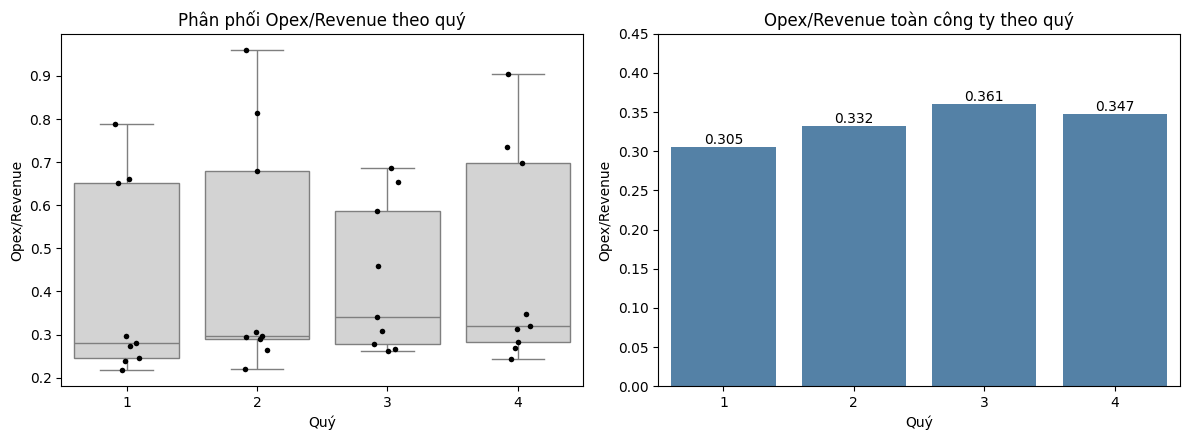

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Biểu đồ 1: Phân phối Opex/Revenue theo quý (mỗi điểm là 1 tháng của 1 dòng sản phẩm)
sns.boxplot(data=pl, x="Quarter", y="Opex_Ratio",
            color="lightgray", showfliers=False, ax=ax[0])
sns.stripplot(data=pl, x="Quarter", y="Opex_Ratio",
              color="black", size=4, ax=ax[0])

ax[0].set_title("Phân phối Opex/Revenue theo quý")
ax[0].set_xlabel("Quý")
ax[0].set_ylabel("Opex/Revenue")

# Biểu đồ 2: Tỷ lệ Opex/Revenue toàn công ty (tổng Opex / tổng doanh thu)
sns.barplot(x=rq2_desc.index, y=rq2_desc["Opex/Revenue toàn doanh nghiệp"],
            color="steelblue", ax=ax[1])
ax[1].bar_label(ax[1].containers[0], fmt="%.3f")

ax[1].set_title("Opex/Revenue toàn công ty theo quý")
ax[1].set_xlabel("Quý")
ax[1].set_ylabel("Opex/Revenue")
ax[1].set_ylim(0, 0.45)

plt.tight_layout()
plt.show()

Nhận xét: Biểu đồ Boxplot cho thấy phân phối Opex/Revenue giữa bốn quý chồng lấn khá nhiều, với trung vị dao động khoảng 0,28–0,34. Xét tỷ lệ Opex/Revenue gộp toàn doanh nghiệp, Quý 1 có tỷ lệ thấp nhất (30,5%), trong khi Quý 3 cao nhất (36,1%). Điều này cho thấy Quý 1 có tỷ lệ chi phí vận hành trên doanh thu thấp nhất. Tuy nhiên đây mới là chênh lệch quan sát được về mặt mô tả, cần kiểm định thống kê để xác định có thực sự khác biệt giữa các quý hay không.

**b. Kiểm tra giả định kiểm định thống kê**

In [ ]:
# Chia dữ liệu Opex/Revenue theo từng quý
groups_q = {
    f"Q{q}": g["Opex_Ratio"].dropna().values
    for q, g in pl.groupby("Quarter")
}

# Kiểm định Shapiro-Wilk
shapiro_q = pd.Series({
    q: shapiro(v).pvalue for q, v in groups_q.items()
})

print("Shapiro-Wilk p-values:")
display(shapiro_q.round(4))

# Kiểm định Levene
print("Levene p-value:", round(levene(*groups_q.values()).pvalue, 4))

Shapiro-Wilk p-values:


,0
Q1,0.0073
Q2,0.0079
Q3,0.0568
Q4,0.0139


Levene p-value: 0.9672


Nhận xét:
- Kiểm định Shapiro-Wilk: Q1, Q2 và Q4 đều cho kết quả p-value nhỏ hơn 0,05 nên bác bỏ giả định phân phối chuẩn ở 3 quý này. Riêng Q3 (p = 0,0568 > 0,05) chưa đủ bằng chứng bác bỏ giả thuyết này.
- Kiểm định Levene: p = 0,9672 > 0,05 do đó không có bằng chứng phương sai khác nhau giữa các quý.

Như vậy, dữ liệu không đáp ứng đầy đủ giả định phân phối chuẩn của ANOVA. Vì vậy nhóm ưu tiên sử dụng Kruskal-Wallis để kiểm định sự khác biệt giữa các quý.

**c. Kiểm định giả thuyết**

In [ ]:
# Kiểm định Kruskal-Wallis
h, p = kruskal(*groups_q.values())

# Kích thước hiệu ứng epsilon² (mức độ khác biệt giữa các quý)
eps2 = h / (len(pl) - 1)

pd.Series({
    "Kruskal-Wallis H": round(h, 2),
    "p-value": f"{p:.3f}",
    "Epsilon²": round(eps2, 3)
})

,0
Kruskal-Wallis H,1.58
p-value,0.664
Epsilon²,0.045


Nhận xét:
- Kiểm định Kruskal-Wallis cho kết quả H = 1,58 và p = 0,664 > 0,05, do đó chưa đủ bằng chứng để bác bỏ H₀, tức chưa phát hiện sự khác biệt có ý nghĩa thống kê về phân phối Opex/Revenue giữa bốn quý.
- Epsilon² = 0,045 cho thấy kích thước hiệu ứng nhỏ, phản ánh sự khác biệt giữa các quý ở mức thấp.
- Vì kiểm định tổng thể không có ý nghĩa thống kê nên không cần thực hiện hậu kiểm so sánh từng cặp quý.

**KẾT LUẬN RQ2**:
- Kết quả kiểm định Kruskal-Wallis cho thấy tỷ lệ Opex/Revenue không khác biệt có ý nghĩa thống kê giữa bốn quý trong năm 2023 nên chưa bác bỏ H₀.
- Về mặt mô tả, Quý 1 là quý có tỷ lệ Opex/Revenue gộp toàn doanh nghiệp thấp nhất (30,5%), còn Quý 3 cao nhất (36,1%). Tuy nhiên do chênh lệch này không có ý nghĩa thống kê nên chưa đủ bằng chứng để khẳng định Quý 1 vận hành hiệu quả hơn các quý còn lại.